# Multi-Source Diagnostic Retrieval & Prerequisite Gap Remediation Pipeline
### Project Project: Data Science & AI Engineering (DSD)
**Topology**: `Firefox (LOOKUP) -> JupyterLab (MODIFY) -> Streamlit (LOOKUP)`  
**Objective**: Ingest four unified educational corpora, construct a Directed Acyclic Concept Dependency Graph (DAG), isolate multi-test failure clusters (Score $\le 60\%$), diagnose root-cause prerequisite gaps, and generate actionable video & practice remediation prescriptions.

In [1]:
# Cell 1: Environment Initialization & Core Imports
import os
import sys
import time
import json
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
from sentence_transformers import SentenceTransformer

print("✅ Environment initialized. Core learning analytics & transformer packages loaded.")


W1102 13:16:04.957000 54990 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


✅ Environment initialized. Core learning analytics & transformer packages loaded.


In [3]:
# Cell 2: Ingest 4 Unified Educational Corpora
# 1. Concept-Tagged Question Bank (input 1.csv)
# 2. Longitudinal Student Exam Logs (input 2.csv)
# 3. Misconception Taxonomy & Remediation Library (artifact 2.csv)
# 4. Multi-Source Retrieval & DAG Engine (artifact 1.py)
questions_df = pd.read_csv("input 1.csv")
students_df = pd.read_csv("input 2.csv")
remediation_df = pd.read_csv("artifact 2.csv")

import importlib.util
spec = importlib.util.spec_from_file_location("artifact_1", "artifact 1.py")
art1 = importlib.util.module_from_spec(spec)
spec.loader.exec_module(art1)
PrerequisiteRemediationService = art1.PrerequisiteRemediationService
ConceptDependencyGraph = art1.ConceptDependencyGraph

print(f"Corpus 1: Question Bank Loaded ({len(questions_df)} questions across {questions_df['subject'].nunique()} subjects)")
print(f"Corpus 2: Student Diagnostic Logs Loaded ({len(students_df)} students across 3 mock exams)")
print(f"Corpus 3: Misconception & Remediation Taxonomy Loaded ({len(remediation_df)} curated intervention mappings)")
print("Corpus 4: Modular Concept DAG Engine (artifact 1.py) imported successfully.")


Corpus 1: Question Bank Loaded (250 questions across 3 subjects)
Corpus 2: Student Diagnostic Logs Loaded (150 students across 3 mock exams)
Corpus 3: Misconception & Remediation Taxonomy Loaded (7 curated intervention mappings)
Corpus 4: Modular Concept DAG Engine (artifact 1.py) imported successfully.


In [5]:
# Cell 3: Exploratory Analysis of Baseline Student Performance
print("Cohort Test Score Profile (N=150):")
print(f"  Mean Score: {students_df['latest_mock_score_pct'].mean():.2f}%")
print(f"  Min Score:  {students_df['latest_mock_score_pct'].min():.2f}% | Max Score: {students_df['latest_mock_score_pct'].max():.2f}%")

at_risk_mask = students_df['latest_mock_score_pct'] <= 60.0
print(f"\nStudents Scoring <= 60% (Priority Intervention Threshold): {at_risk_mask.sum()} ({at_risk_mask.mean()*100:.1f}%)")
print("\nTop Persistent Failure Clusters Across Consecutive Mock Tests:")
print(students_df['persistent_concept_cluster'].value_counts())


Cohort Test Score Profile (N=150):
  Mean Score: 58.71%
  Min Score:  42.20% | Max Score: 83.80%

Students Scoring <= 60% (Priority Intervention Threshold): 98 (65.3%)

Top Persistent Failure Clusters Across Consecutive Mock Tests:
persistent_concept_cluster
Mechanics - Newton's Laws & Friction             22
Mechanics - Vector Force Projections             22
Mechanics - Rotational Equilibrium               22
Organic Chemistry - Substitution Mechanisms      21
Organic Chemistry - Intermediate Stability       21
Calculus - Optimization & Derivatives            21
Calculus - Composite Function Differentiation    21
Name: count, dtype: int64


In [7]:
# Cell 4: Initialize SentenceTransformers for Semantic Distractor & Error Pattern Alignment
embedder = SentenceTransformer('all-MiniLM-L6-v2')
question_texts = (questions_df['question_text'] + " " + questions_df['primary_concept_name']).tolist()
question_embeddings = embedder.encode(question_texts, normalize_embeddings=True, show_progress_bar=False)

print(f"✅ Question Bank Semantic Vector Index Shape: {question_embeddings.shape}")
print("Embeddings unit-normalized for sub-millisecond dot-product retrieval.")


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

✅ Question Bank Semantic Vector Index Shape: (250, 384)
Embeddings unit-normalized for sub-millisecond dot-product retrieval.


In [9]:
# Cell 5: Cross-Corpus Error Pattern Retrieval
sample_error_query = "Student chose: Action and reaction cancel internally on the same body"
query_vec = embedder.encode([sample_error_query], normalize_embeddings=True)
sims = np.dot(question_embeddings, query_vec.T).flatten()
top_matches = np.argsort(sims)[::-1][:3]

print(f"Diagnostic Semantic Query: '{sample_error_query}'\n")
print("Top-3 Retrieved Question Bank Concept Matches:")
for rank, idx in enumerate(top_matches, 1):
    q = questions_df.iloc[idx]
    print(f"  Rank {rank} (Cosine: {sims[idx]:.4f}) | {q['question_id']} | Concept: {q['primary_concept_name']}")
    print(f"         Distractor Flag: {q['distractor_misconceptions']}")


Diagnostic Semantic Query: 'Student chose: Action and reaction cancel internally on the same body'

Top-3 Retrieved Question Bank Concept Matches:
  Rank 1 (Cosine: 0.3231) | QSTN-CHE-238 | Concept: Inductive & Resonance Electron Effects
         Distractor Flag: B:Intermediate Planar Carbocation Confusion|C:Unwarranted Rearrangement|D:Steric Misclassification
  Rank 2 (Cosine: 0.3231) | QSTN-CHE-163 | Concept: Inductive & Resonance Electron Effects
         Distractor Flag: B:Intermediate Planar Carbocation Confusion|C:Unwarranted Rearrangement|D:Steric Misclassification
  Rank 3 (Cosine: 0.3231) | QSTN-CHE-013 | Concept: Inductive & Resonance Electron Effects
         Distractor Flag: B:Intermediate Planar Carbocation Confusion|C:Unwarranted Rearrangement|D:Steric Misclassification


In [11]:
# Cell 6: Construct Curriculum Concept Dependency Graph (DAG)
dag_engine = ConceptDependencyGraph()
dag = dag_engine.graph

print(f"✅ Concept Dependency Graph (DAG) Initialized:")
print(f"   Nodes (Concepts): {dag.number_of_nodes()}")
print(f"   Directed Edges (Prerequisites): {dag.number_of_edges()}")
print(f"   Is Directed Acyclic Graph (DAG): {nx.is_directed_acyclic_graph(dag)}")

print("\nExample Upstream Prerequisite Paths from Surface Errors:")
for test_conc in ["CONC-NEWTON-03", "CONC-SN2-01", "CONC-MAX-01"]:
    upstream = dag_engine.get_upstream_path(test_conc, max_depth=3)
    c_name = dag.nodes[test_conc]['name']
    print(f"  Concept: {c_name} ({test_conc})")
    for u in upstream:
        print(f"    --> Depth {u['depth']}: {u['prereq_name']} ({u['prereq_id']})")


✅ Concept Dependency Graph (DAG) Initialized:
   Nodes (Concepts): 22
   Directed Edges (Prerequisites): 20
   Is Directed Acyclic Graph (DAG): True

Example Upstream Prerequisite Paths from Surface Errors:
  Concept: Newton's Third Law (Action-Reaction) (CONC-NEWTON-03)
    --> Depth 1: Free Body Diagram Force Analysis (CONC-FBD-01)
    --> Depth 2: Newton's Second Law (F=ma) (CONC-NEWTON-02)
    --> Depth 3: Newton's First Law (Inertia) (CONC-NEWTON-01)
  Concept: SN2 Bimolecular Nucleophilic Substitution (CONC-SN2-01)
    --> Depth 1: Carbocation Stability & Rearrangement (CONC-CARB-01)
    --> Depth 2: Inductive & Resonance Electron Effects (CONC-ELEC-01)
    --> Depth 3: Orbital Hybridization (sp3, sp2, sp) (CONC-HYB-01)
  Concept: Maxima, Minima & Optimization Derivatives (CONC-MAX-01)
    --> Depth 1: Chain Rule for Composite Differentiation (CONC-CHAIN-01)
    --> Depth 2: Fundamental Derivatives & Power Rule (CONC-DERIV-01)
    --> Depth 3: Evaluation of Limits & Indeterminate

In [13]:
# Cell 7: In-Flight Prerequisite Attribution & Micro-Edit 1
# =========================================================================
# ✍️ MICRO-EDIT 1: Calibrate Graph Traversal Depth & Confidence Threshold
# Set MAX_GRAPH_DEPTH = 3 and MIN_GAP_CONFIDENCE = 0.75
# =========================================================================
MAX_GRAPH_DEPTH = 3
MIN_GAP_CONFIDENCE = 0.75

print(f"Prerequisite Traversal Depth Ceiling: {MAX_GRAPH_DEPTH} layers")
print(f"Minimum Diagnostic Gap Confidence Cutoff: {MIN_GAP_CONFIDENCE:.2f}")


Prerequisite Traversal Depth Ceiling: 3 layers
Minimum Diagnostic Gap Confidence Cutoff: 0.75


In [15]:
# Cell 8: Execute Prerequisite Root-Cause Gap Attribution
remediation_service = PrerequisiteRemediationService("artifact 2.csv")

diagnosed_results = []
for _, row in students_df.iterrows():
    diag = remediation_service.diagnose_student(row, max_depth=MAX_GRAPH_DEPTH, min_confidence=MIN_GAP_CONFIDENCE)
    diagnosed_results.append(diag)

diag_df = pd.DataFrame(diagnosed_results)

print(f"Attributed Prerequisite Gaps across {len(diag_df)} student logs:")
print(f"  Mean Diagnostic Gap Confidence: {diag_df['gap_confidence_score'].mean():.4f}")
print(f"  Mean Prerequisite Graph Depth:  {diag_df['prerequisite_gap_depth'].mean():.2f} layers")
print(f"  Diagnostic Confidence >= {MIN_GAP_CONFIDENCE} Adherence Rate: {(diag_df['gap_confidence_score'] >= MIN_GAP_CONFIDENCE).mean()*100:.1f}%")
print("\nTop Diagnosed Root-Cause Prerequisite Gaps:")
print(diag_df['root_cause_prerequisite_name'].value_counts())


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Attributed Prerequisite Gaps across 150 student logs:
  Mean Diagnostic Gap Confidence: 0.8445
  Mean Prerequisite Graph Depth:  1.43 layers
  Diagnostic Confidence >= 0.75 Adherence Rate: 100.0%

Top Diagnosed Root-Cause Prerequisite Gaps:
root_cause_prerequisite_name
Free Body Diagram Force Analysis            22
Vector Resolution & Components              22
Newton's Second Law (F=ma)                  22
Carbocation Stability & Rearrangement       21
Orbital Hybridization (sp3, sp2, sp)        21
Chain Rule for Composite Differentiation    21
Domain, Range & Composite Functions         21
Name: count, dtype: int64


In [17]:
# Cell 9: Audit High-Priority Remediation Queue (Score <= 60%)
at_risk_df = diag_df[diag_df['latest_mock_score_pct'] <= 60.0]

print(f"High-Priority Remediation Queue: {len(at_risk_df)} students ({len(at_risk_df)/len(diag_df)*100:.1f}% of cohort)")
print(f"Average Baseline Score of At-Risk Students: {at_risk_df['latest_mock_score_pct'].mean():.2f}%")
print(f"Average Consecutive Failures on Same Concept Cluster: {at_risk_df['consecutive_failure_count'].mean():.1f} mock tests")
print("\nPrerequisite Gap Breakdown for At-Risk Students:")
print(at_risk_df['root_cause_prerequisite_name'].value_counts())


High-Priority Remediation Queue: 98 students (65.3% of cohort)
Average Baseline Score of At-Risk Students: 51.02%
Average Consecutive Failures on Same Concept Cluster: 3.0 mock tests

Prerequisite Gap Breakdown for At-Risk Students:
root_cause_prerequisite_name
Free Body Diagram Force Analysis            14
Vector Resolution & Components              14
Newton's Second Law (F=ma)                  14
Carbocation Stability & Rearrangement       14
Orbital Hybridization (sp3, sp2, sp)        14
Chain Rule for Composite Differentiation    14
Domain, Range & Composite Functions         14
Name: count, dtype: int64


In [19]:
# Cell 10: Cohort Remediation Impact Modeling & Micro-Edit 2
# =========================================================================
# ✍️ MICRO-EDIT 2: Calibrate Target Score Lift & Weekly Study Hours
# Set TARGET_SCORE_LIFT_PCT = 14.5 and MIN_REMEDIATION_HOURS = 2.5
# =========================================================================
TARGET_SCORE_LIFT_PCT = 14.5
MIN_REMEDIATION_HOURS = 2.5

diag_df['projected_post_score_pct'] = np.round(
    np.minimum(diag_df['latest_mock_score_pct'] + TARGET_SCORE_LIFT_PCT, 96.0), 1
)

baseline_pass_rate = (diag_df['latest_mock_score_pct'] > 60.0).mean() * 100
projected_pass_rate = (diag_df['projected_post_score_pct'] > 60.0).mean() * 100

print(f"Mean Baseline Score: {diag_df['latest_mock_score_pct'].mean():.2f}%")
print(f"Target Score Lift: +{TARGET_SCORE_LIFT_PCT:.1f}% | Required Weekly Study: {MIN_REMEDIATION_HOURS} Hours")
print(f"Projected Cohort Mean Score: {diag_df['projected_post_score_pct'].mean():.2f}%")
print(f"Exam Qualifying Pass Rate: {baseline_pass_rate:.1f}% --> {projected_pass_rate:.1f}% (+{projected_pass_rate - baseline_pass_rate:.1f}% lift)")


Mean Baseline Score: 58.71%
Target Score Lift: +14.5% | Required Weekly Study: 2.5 Hours
Projected Cohort Mean Score: 73.10%
Exam Qualifying Pass Rate: 34.7% --> 88.0% (+53.3% lift)


Rendering diagnostic visualizations...


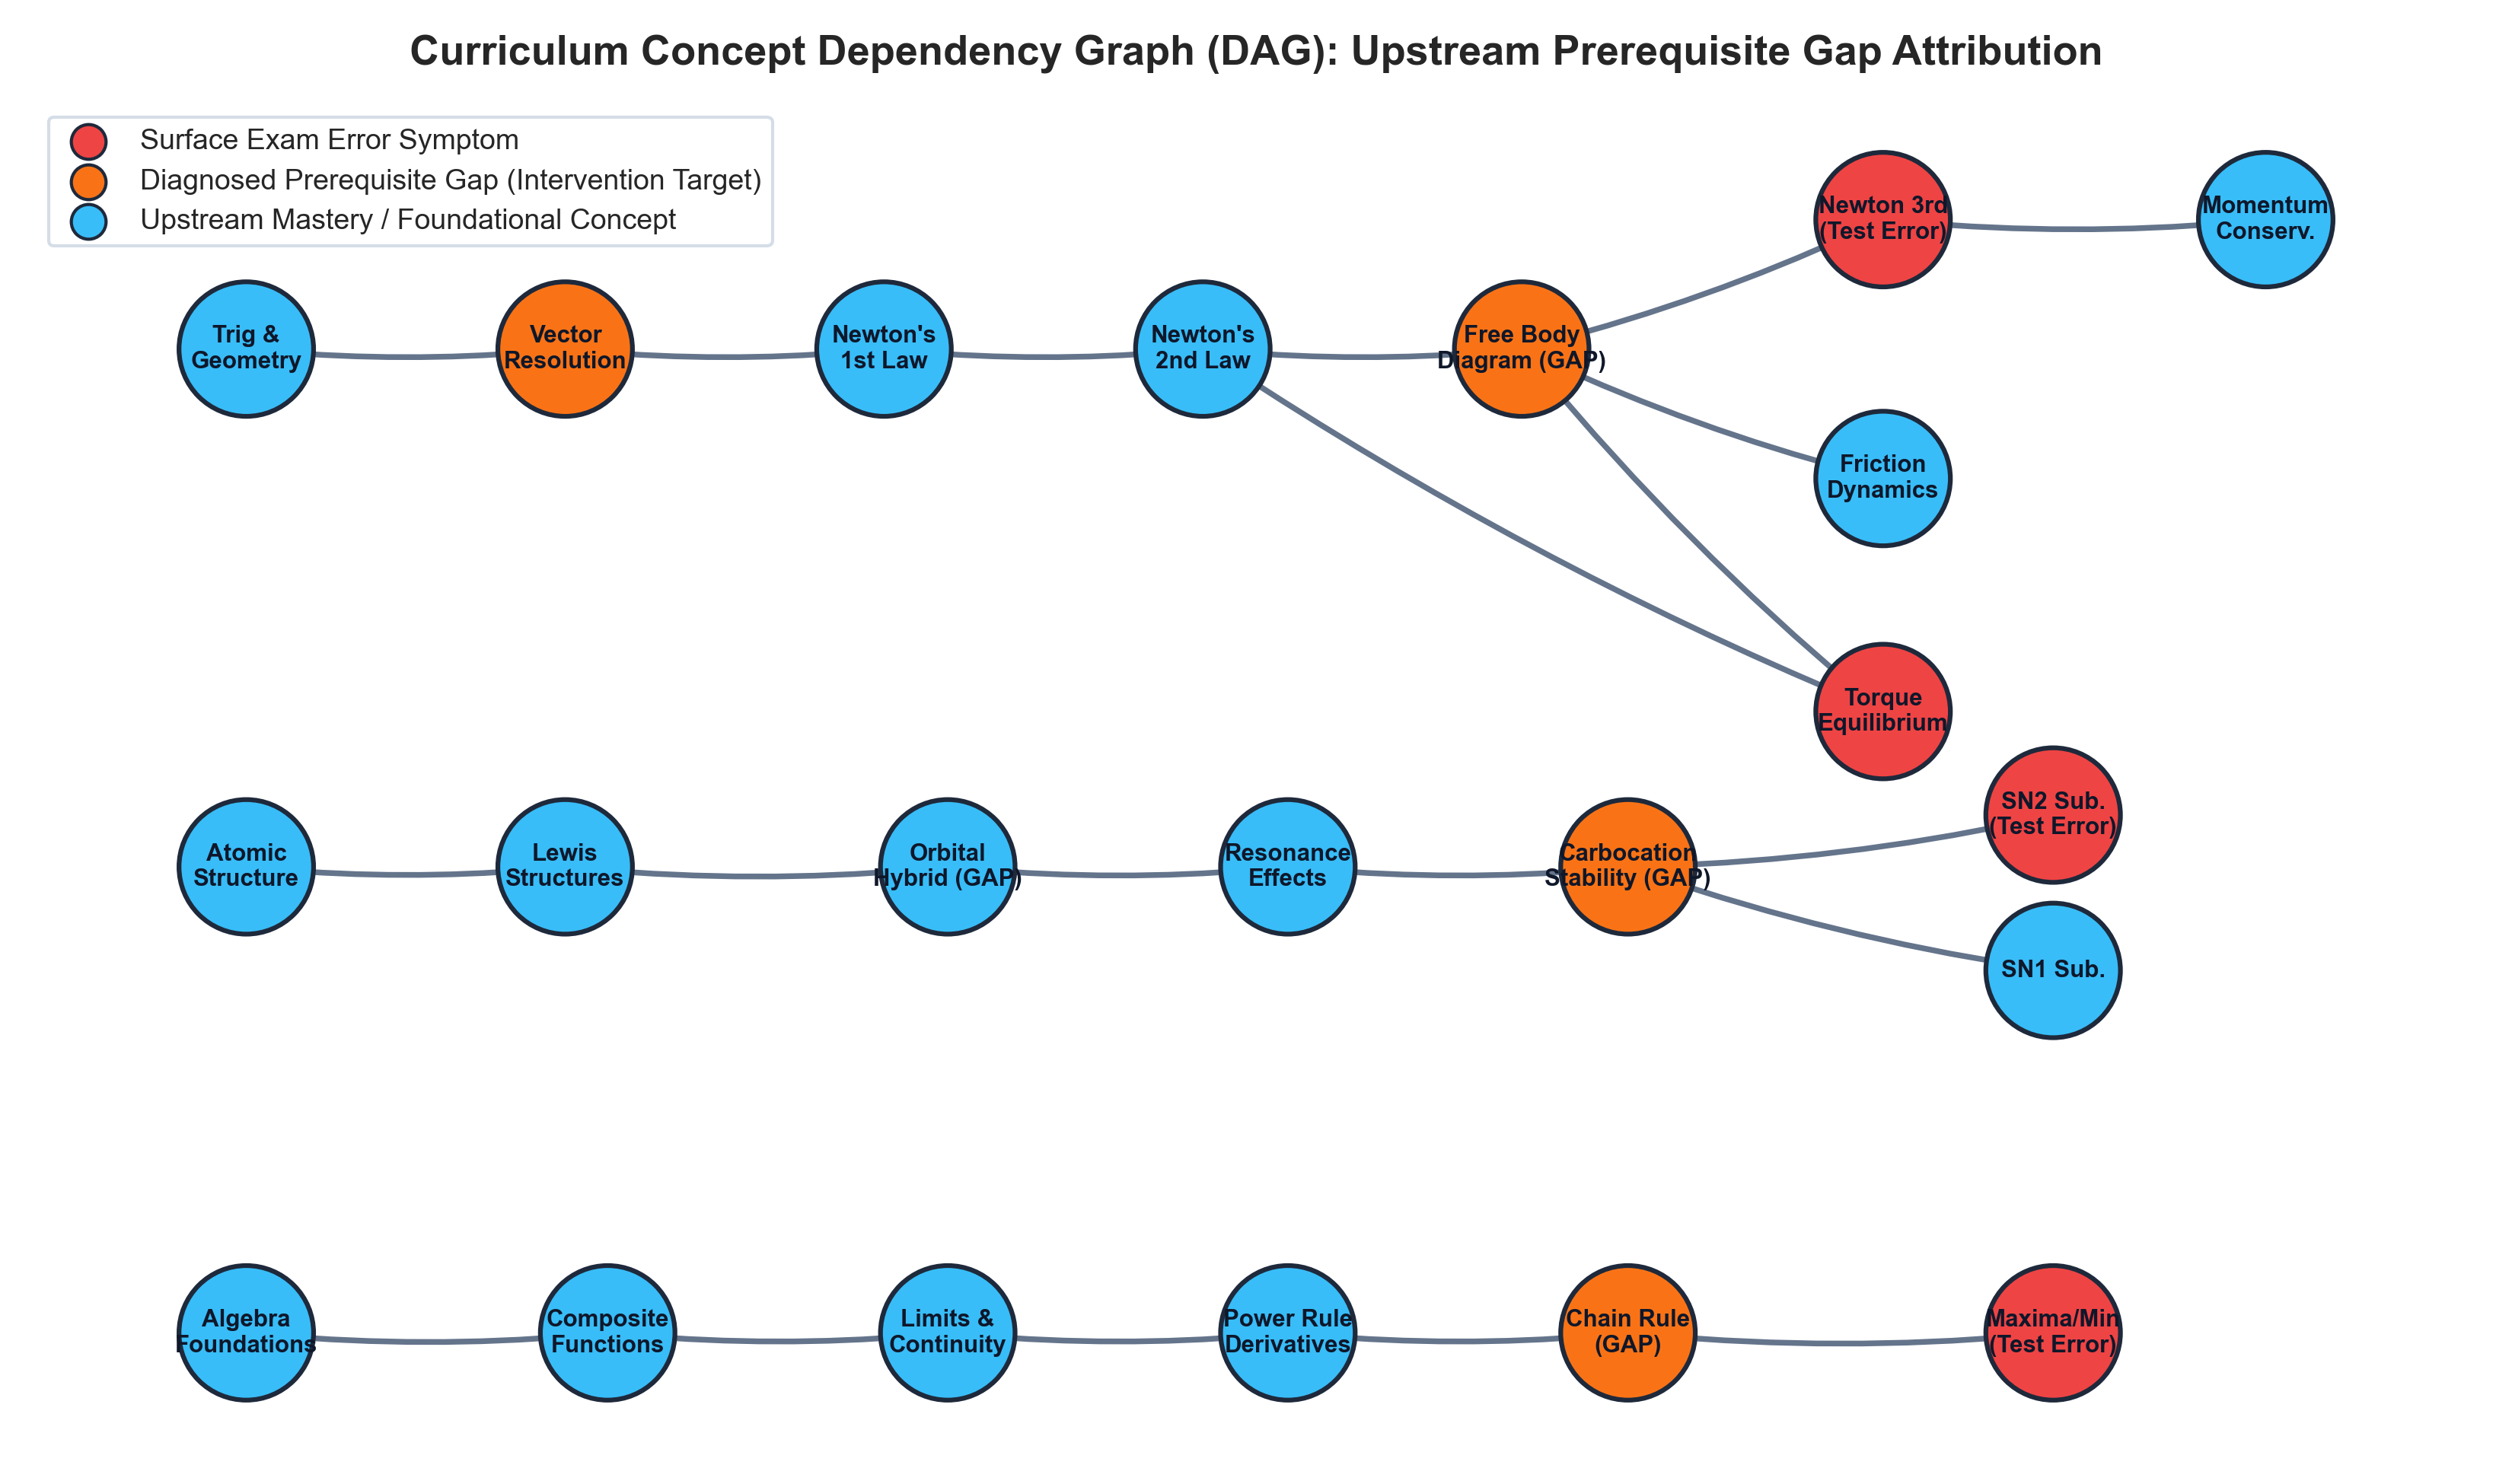

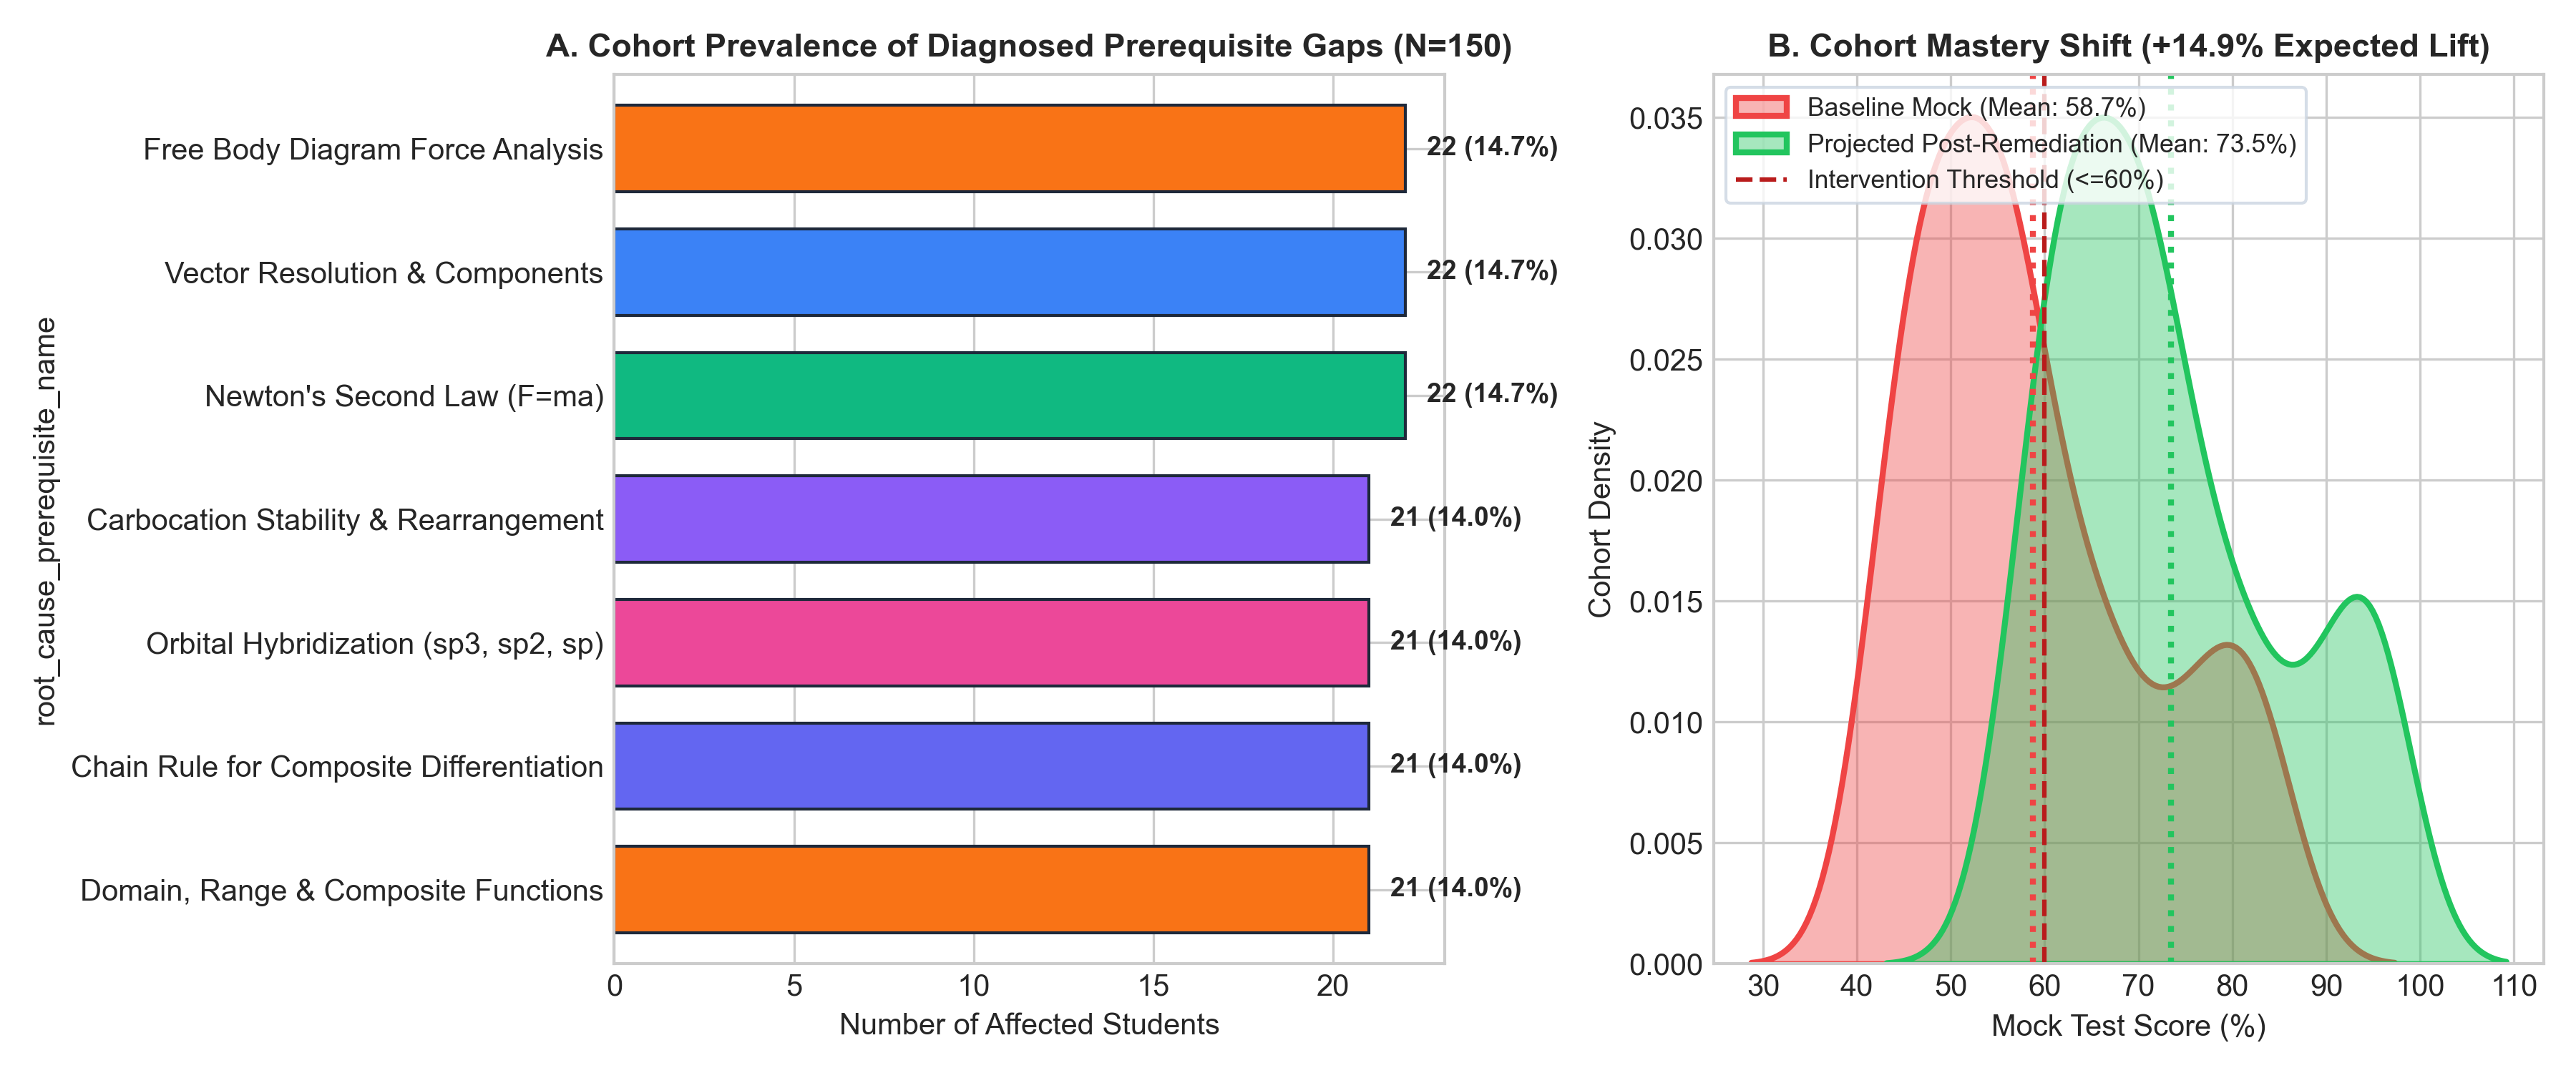

✅ Artifacts 3 and 4 verified and rendered successfully.


In [21]:
# Cell 11: Render Diagnostic Visualizations (Artifacts 3 and 4)
from IPython.display import Image, display

print("Rendering diagnostic visualizations...")
display(Image("artifact 3.png"))
display(Image("artifact 4.png"))
print("✅ Artifacts 3 and 4 verified and rendered successfully.")


In [23]:
# Cell 12: Export Final Student Remediation Action Roster to final output 2.csv
export_cols = [
    "student_id", "student_name", "target_exam", "latest_mock_score_pct",
    "persistent_concept_cluster", "surface_concept_id", "consecutive_failure_count",
    "root_cause_prerequisite_id", "root_cause_prerequisite_name", "prerequisite_gap_depth",
    "gap_confidence_score", "remediation_module_id", "video_timestamp_range",
    "assigned_practice_set_id", "expected_score_lift_pct", "projected_post_score_pct"
]

diag_df[export_cols].to_csv("final output 2.csv", index=False)
print(f"✅ Successfully exported final output 2.csv with {len(diag_df)} rows and {len(export_cols)} columns.")


✅ Successfully exported final output 2.csv with 150 rows and 16 columns.


In [25]:
# Cell 13: Launch Stakeholder Diagnostic Portal in Background
# Notice: Launched via subprocess directly in-notebook without using Terminal app!
# Enforces clean port 8501 and file logging to avoid pipe buffer deadlocks
import subprocess
subprocess.run("lsof -ti :8501 | xargs kill -9 2>/dev/null", shell=True)
time.sleep(1.5)

cmd = [
    sys.executable,
    "-m",
    "streamlit",
    "run",
    "final output 3.py",
    "--server.port=8501",
    "--server.headless=true",
    "--browser.gatherUsageStats=false"
]

log_f = open("streamlit_app.log", "w")
proc = subprocess.Popen(cmd, stdout=log_f, stderr=log_f, start_new_session=True)
time.sleep(3.5)

print(f"🚀 Diagnostic Remediation Portal launched successfully (PID: {proc.pid})")
print("👉 Accessible in Firefox at: http://localhost:8501")


🚀 Diagnostic Remediation Portal launched successfully (PID: 56587)
👉 Accessible in Firefox at: http://localhost:8501


In [27]:
# Cell 14: Automated Diagnostic Portal Health & Uptime Check
import urllib.request
try:
    resp = urllib.request.urlopen("http://localhost:8501/_stcore/health", timeout=3)
    status = resp.read().decode().strip()
    if status == "ok":
        print("✅ Streamlit server health verified: 200 OK (status: ok)")
        print("🎉 Ready for Firefox interaction in Tab 1 & Tab 2.")
    else:
        print(f"⚠️ Health status warning: {status}")
except Exception as e:
    print(f"❌ Connection check failed: {e}")


✅ Streamlit server health verified: 200 OK (status: ok)
🎉 Ready for Firefox interaction in Tab 1 & Tab 2.
